# A4 bare fields: which months cropland is usually bare

The PRD method smooths each LGA's 16-day cropland NDVI with Savitzky-Golay (window 5, order 2), then marks composites below a bare threshold. This notebook compares it with its baseline (the same threshold on raw NDVI) and compares the PRD's fixed 0.25 threshold with the per-LGA threshold `data/ndvi_gee.py` uses. Better detection means fewer bare-to-green flips inside a year and closer agreement with the known dry season (November to April).

Formulas: `model/bare_fields.py`. Settings: `config/models.yaml` (`bare_fields`).

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import bare_fields as bf
from model import experiments
from model.experiments import log_experiments
from model.io import write_csv
from model.settings import load_model_config

## 1. Load the cropland NDVI composites

In [4]:
# Load the 16-day cropland NDVI composites (2000 to 2024), sorted by LGA and date, and
# report how many there are and what share was cloud-filled.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
b = cfg.bare_fields
comp = pd.read_csv(cfg.paths.ndvi_composites, parse_dates=["date"])
comp = comp[comp["year"].between(b.years.start, b.years.end)].dropna(subset=["ndvi_crop"])
comp = comp.sort_values(["lga", "date"]).reset_index(drop=True)
{
    "composites": len(comp),
    "per LGA-year": int(comp.groupby(["lga", "year"]).size().median()),
    "cloud-filled share": round(comp["interpolated"].mean(), 3),
}

{'composites': 13087,
 'per LGA-year': 23,
 'cloud-filled share': np.float64(0.085)}

## 2. Four ways to flag a bare composite

In [5]:
# Flag every composite bare four ways (raw or smoothed NDVI, per-LGA or fixed threshold),
# then score each method on flips per year and dry-season agreement, over all 23 LGAs.
comp["bare_raw_relative"] = comp["ndvi_crop"] < bf.relative_threshold(
    comp["ndvi_crop"], comp["lga"], b.relative_fraction
)
comp["bare_smoothed_relative"] = comp["ndvi_crop_sg"] < bf.relative_threshold(
    comp["ndvi_crop_sg"], comp["lga"], b.relative_fraction
)
comp["bare_raw_absolute"] = comp["ndvi_crop"] < b.absolute_threshold
comp["bare_smoothed_absolute"] = comp["ndvi_crop_sg"] < b.absolute_threshold
flags = {
    "raw, per-LGA threshold": "bare_raw_relative",
    "smoothed, per-LGA threshold": "bare_smoothed_relative",
    "raw, fixed 0.25": "bare_raw_absolute",
    "smoothed, fixed 0.25": "bare_smoothed_absolute",
}
scores = bf.method_scores(comp, flags, b.dry_season_months)
scores.round(3)

,method,flips_per_year_mean,flips_per_year_median,dry_season_agreement
0,"raw, per-LGA threshold",2.017,2.0,0.857
1,"smoothed, per-LGA threshold",1.990,2.0,0.859
2,"raw, fixed 0.25",1.243,1.0,0.620
3,"smoothed, fixed 0.25",1.080,1.0,0.620


**Reading.** Smoothing barely changes anything here: averaging NDVI over a whole LGA's cropland already removes most cloud noise. The threshold is what matters: a per-LGA threshold matches the dry season far better than a fixed 0.25, which never fires in the southern LGAs where trees in the farm mosaic keep dry-season NDVI near 0.30. The smoothed, per-LGA method is kept.

## 3. A worked example: one LGA, one year (section 4 covers all 23)

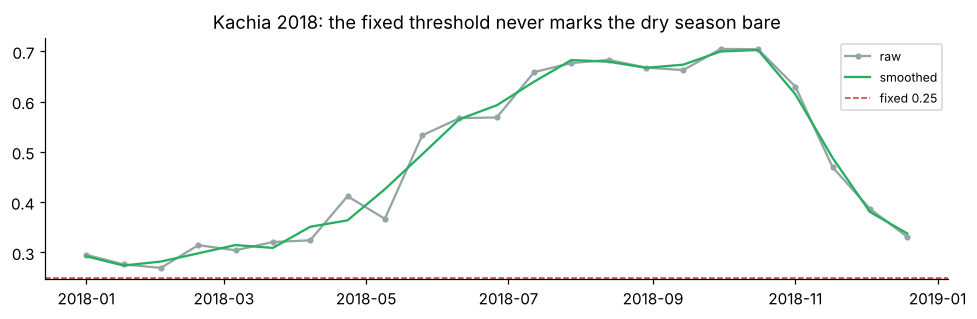

In [6]:
# Worked example: Kachia 2018, raw against smoothed NDVI, with the fixed 0.25 threshold.
sample = comp[(comp["lga"] == "Kachia") & (comp["year"] == 2018)]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(sample["date"], sample["ndvi_crop"], marker=".", color="#95a5a6", label="raw")
ax.plot(sample["date"], sample["ndvi_crop_sg"], color="#27ae60", label="smoothed")
ax.axhline(b.absolute_threshold, ls="--", color="#c0392b", lw=1, label="fixed 0.25")
ax.legend(fontsize=8)
ax.set_title("Kachia 2018: the fixed threshold never marks the dry season bare")
plt.tight_layout()

## 4. Bare probability for all 23 LGAs and every month

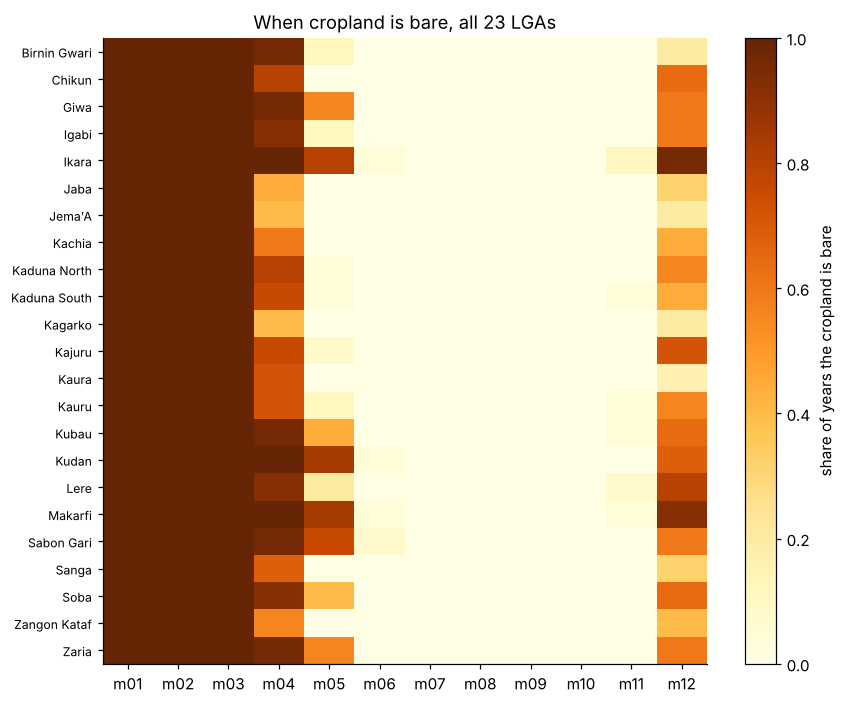

In [7]:
# All 23 LGAs: share of years each month's cropland is bare, by the kept method.
prob_all = bf.bare_probability(
    comp["bare_smoothed_relative"], comp["lga"], comp["year"], comp["month"]
)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(prob_all, cmap="YlOrBr", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(prob_all.shape[1]), prob_all.columns)
ax.set_yticks(range(len(prob_all)), prob_all.index, fontsize=8)
fig.colorbar(im, label="share of years the cropland is bare")
ax.set_title("When cropland is bare, all 23 LGAs")
plt.tight_layout()

## 5. Save and log

In [8]:
# Save the bare probability table and the method scores, and log the four methods.
prob = prob_all
out = cfg.paths.output_dir / "a4"
write_csv(prob.reset_index(names="lga"), out / "a4_bare_probability.csv")
write_csv(scores, out / "a4_method_scores.csv")
rows = [
    experiments.component_row(
        f"A4 {r.method}",
        "MODIS MOD13Q1 cropland NDVI, 16-day",
        "2000-2024, all LGAs",
        {
            "flips_per_year_mean": round(r.flips_per_year_mean, 3),
            "dry_season_agreement": round(r.dry_season_agreement, 3),
        },
        "kept" if r.method == "smoothed, per-LGA threshold" else "",
        experiments.today(),
    )
    for r in scores.itertuples()
]
log_experiments(cfg.paths.experiment_log, rows)
prob.round(2).head()

,m01,m02,m03,m04,m05,m06,m07,m08,m09,m10,m11,m12
lga,,,,,,,,,,,,
Birnin Gwari,1.0,1.0,1.0,0.96,0.12,0.00,0.0,0.0,0.0,0.0,0.00,0.20
Chikun,1.0,1.0,1.0,0.80,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.64
Giwa,1.0,1.0,1.0,0.96,0.56,0.00,0.0,0.0,0.0,0.0,0.00,0.60
Igabi,1.0,1.0,1.0,0.92,0.12,0.00,0.0,0.0,0.0,0.0,0.00,0.60
Ikara,1.0,1.0,1.0,1.00,0.80,0.04,0.0,0.0,0.0,0.0,0.12,0.96
